In [3]:
import os
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu
from collections import defaultdict
import matplotlib.pyplot as plt

In [4]:
datadir = "../resources/developed"

In [5]:
# (N=281589)
gecodb_v07 = pd.read_csv(
    os.path.join(datadir, "gecodb_v07.tsv"),
    sep="\t",
    dtype=defaultdict(
        lambda: str,
        **{
            f"{prx}_freq": int
            for prx in ["comp", "n1", "n2"]
        },
        n1_prod="int",
        umlaut_applied="bool"
    ),
    header=0,
    index_col=0
)

gecodb_v07.sample(10)

,comp_lemma,comp_freq,n1_lemma,n1_freq,n1_prod,linker,umlaut_applied,n2_lemma,n2_freq
comp_gecodb,,,,,,,,,
stadt_marke,Stadtmarke,336,stadt,9376427,914,_,False,marke,663106
wirtschaft_+s_egoismus,Wirtschaftsegoismus,24,wirtschaft,1763302,683,_+s_,False,egoismus,24424
gut_+=er_korridor,Güterkorridor,34,gut,425955,153,_+=er_,True,korridor,34312
frau_+en_zoo,Frauenzoo,47,frau,9838661,607,_+en_,False,zoo,298192
beschäftigung_+s_spiel,Beschäftigungsspiel,56,beschäftigung,265093,183,_+s_,False,spiel,5073662
laie_+n_presse,Laienpresse,52,laie,119830,105,_+n_,False,presse,362515
verfassung_+s_norm,Verfassungsnorm,543,verfassung,334900,173,_+s_,False,norm,117080
stroh_anhänger,Strohanhänger,41,stroh,58625,114,_,False,anhänger,501658
therme_+n_museum,Thermenmuseum,162,therme,37316,30,_+n_,False,museum,1615048


In [6]:
# to investigate the effect of the umlaut on
# plural effect, we disambugate between -"er- and -er- here
er_numl = gecodb_v07[
    (gecodb_v07["linker"] == "_+=er_") &
    ~(gecodb_v07["umlaut_applied"])
]
gecodb_v07.loc[er_numl.index, "linker"] = "_+er_"

In [7]:
# filter out N1s that may not attach pl linkers
plls = [
    "_+n_", "_+en_",
    "_+e_", "_+=e_",
    "_+=_",
    "_+er_", "_+=er_"
]

gecodb_v07pl_n1s = gecodb_v07[gecodb_v07["linker"].isin(plls)]  \
    ["n1_lemma"].unique()
gecodb_v07pl = gecodb_v07[gecodb_v07["n1_lemma"].isin(gecodb_v07pl_n1s)]
gecodb_v07pl.insert(
    6, "is_pll",
    gecodb_v07pl["linker"].isin(plls)
)
# (N=96968, pll N=42950, npll N =54018)
gecodb_v07pl.to_csv(
    os.path.join(datadir, "gecodb_v07pl.tsv"),
    sep="\t",
    header=True,
    index=True
)
gecodb_v07pl

,comp_lemma,comp_freq,n1_lemma,n1_freq,n1_prod,linker,is_pll,umlaut_applied,n2_lemma,n2_freq
comp_gecodb,,,,,,,,,,
land_kreis,Landkreis,2038715,land,8929250,1167,_,False,False,kreis,2731589
land_+es_regierung,Landesregierung,777779,land,8929250,1167,_+es_,False,False,regierung,2648830
land_gericht,Landgericht,576177,land,8929250,1167,_,False,False,gericht,1784349
land_wirt,Landwirt,457461,land,8929250,1167,_,False,False,wirt,157625
land_+es_verband,Landesverband,210578,land,8929250,1167,_+es_,False,False,verband,1138891
...,...,...,...,...,...,...,...,...,...,...
printe_+n_könig,Printenkönig,45,printe,4777,11,_+n_,True,False,könig,838289
printe_+n_teig,Printenteig,35,printe,4777,11,_+n_,True,False,teig,71418
printe_+n_kegel,Printenkegel,52,printe,4777,11,_+n_,True,False,kegel,69838


In [8]:
# filter out N1s that mostly attach pll/npll
pll_counts = pd.DataFrame({
    n1: {
        "pll": len(
            gecodb_v07pl[
                (gecodb_v07pl["n1_lemma"] == n1) &
                gecodb_v07pl["is_pll"]
            ]
        ),
        "npll": len(
            gecodb_v07pl[
                (gecodb_v07pl["n1_lemma"] == n1) &
                ~gecodb_v07pl["is_pll"]
            ]
        )
    }
    for n1 in gecodb_v07pl["n1_lemma"].unique()
}).T
pll_counts

,pll,npll
land,226,937
kind,947,100
wasser,1,939
spiel,166,693
bild,216,456
...,...,...
hüne,5,3
vorwoche,12,0
adduktor,10,0
kuriosität,10,0


In [9]:
pll_counts["pll_shape"] = pll_counts["pll"] / pll_counts.sum(axis=1)
pll_counts

,pll,npll,pll_shape
land,226,937,0.194325
kind,947,100,0.904489
wasser,1,939,0.001064
spiel,166,693,0.193248
bild,216,456,0.321429
...,...,...,...
hüne,5,3,0.625000
vorwoche,12,0,1.000000
adduktor,10,0,1.000000
kuriosität,10,0,1.000000


In [10]:
balanced_n1s = pll_counts[
    (pll_counts["pll_shape"] >= 0.25) &
    (pll_counts["pll_shape"] <= 0.75)
].index
balanced_n1s

Index(['bild', 'buch', 'stern', 'geist', 'probe', 'gott', 'motor', 'gast',
       'weg', 'anlage', 'punkt', 'wert', 'ei', 'mitglied', 'kohle', 'maus',
       'schuld', 'norm', 'geschlecht', 'geburt', 'ohr', 'bad', 'ausgabe',
       'rasse', 'bett', 'lied', 'weide', 'szene', 'last', 'gut', 'korn', 'art',
       'geschenk', 'recht', 'generation', 'frage', 'schwester', 'vater',
       'abgabe', 'spur', 'asche', 'junior', 'einnahme', 'mitte', 'brett',
       'dorn', 'bruder', 'minderheit', 'kalb', 'melodie', 'kategorie',
       'vorlage', 'traktor', 'einlage', 'rate', 'anleihe', 'aue', 'witz',
       'priorität', 'hahn', 'indikator', 'nation', 'generator', 'unterschrift',
       'frist', 'mulde', 'institution', 'schlacke', 'kompressor', 'laus',
       'tide', 'hemd', 'rüge', 'miliz', 'waage', 'zeh', 'schlucht', 'neuheit',
       'weite', 'anhalt', 'wehe', 'henne', 'made', 'kanne', 'konditor',
       'rektor', 'transformator', 'ranke', 'kaper', 'zugabe', 'elle',
       'rücklage', 'karikatu

In [11]:
gecodb_v07pl = gecodb_v07pl[gecodb_v07pl["n1_lemma"].isin(balanced_n1s)]
gecodb_v07pl

,comp_lemma,comp_freq,n1_lemma,n1_freq,n1_prod,linker,is_pll,umlaut_applied,n2_lemma,n2_freq
comp_gecodb,,,,,,,,,,
bild_qualität,Bildqualität,9525,bild,3732418,672,_,False,False,qualität,940698
bild_material,Bildmaterial,13966,bild,3732418,672,_,False,False,material,698223
bild_+=er_galerie,Bildergalerie,16699,bild,3732418,672,_+er_,True,False,galerie,442177
bild_+=er_buch,Bilderbuch,40509,bild,3732418,672,_+er_,True,False,buch,2731652
bild_bearbeitung,Bildbearbeitung,9280,bild,3732418,672,_,False,False,bearbeitung,103559
...,...,...,...,...,...,...,...,...,...,...
hüne_+n_stein,Hünenstein,101,hüne,15531,8,_+n_,True,False,stein,884861
hüne_+n_weg,Hünenweg,29,hüne,15531,8,_+n_,True,False,weg,5133691
hüne_meier,Hünemeier,1041,hüne,15531,8,_,False,False,meier,228573


In [12]:
all(pll in gecodb_v07pl["linker"].unique() for pll in plls)

True

<Axes: >

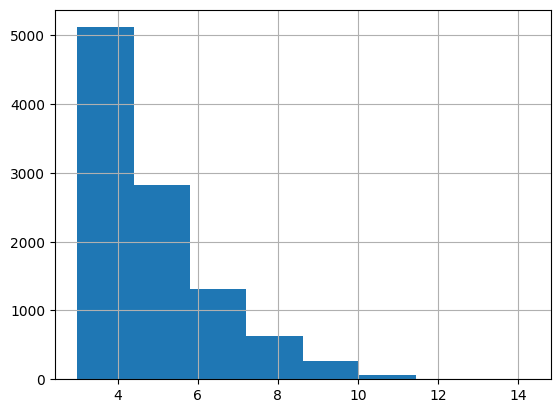

In [13]:
cf_logs = np.log(gecodb_v07pl["comp_freq"])
cf_logs.hist(bins=8)

In [14]:
cf_logs_min = cf_logs.min()
cf_logs_max = cf_logs.max()
cf_logs_scale = np.linspace(cf_logs_min, cf_logs_max, num=8)
cf_logs_scale

array([ 2.99573227,  4.60498923,  6.21424618,  7.82350313,  9.43276008,
       11.04201703, 12.65127399, 14.26053094])

<Axes: >

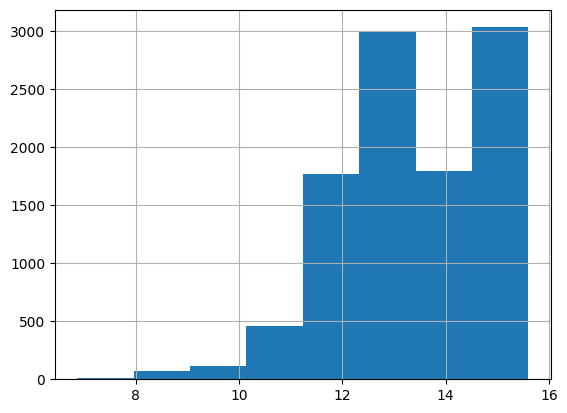

In [15]:
n1f_logs = np.log(gecodb_v07pl["n1_freq"])
n1f_logs.hist(bins=8)

In [16]:
n1f_logs_min = n1f_logs.min()
n1f_logs_max = n1f_logs.max()
n1f_logs_scale = np.linspace(n1f_logs_min, n1f_logs_max, num=8)
n1f_logs_scale

array([ 6.87316383,  8.11997221,  9.36678058, 10.61358896, 11.86039733,
       13.1072057 , 14.35401408, 15.60082245])

<Axes: >

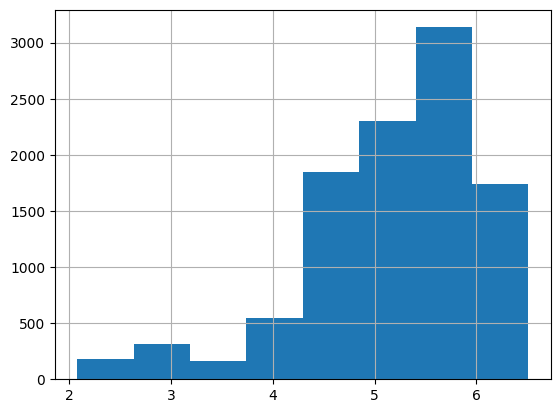

In [17]:
n1p_logs = np.log(gecodb_v07pl["n1_prod"])
n1p_logs.hist(bins=8)

In [18]:
n1p_logs_min = n1p_logs.min()
n1p_logs_max = n1p_logs.max()
n1p_logs_scale = np.linspace(n1p_logs_min, n1p_logs_max, num=8)
n1p_logs_scale

array([2.07944154, 2.71241537, 3.3453892 , 3.97836303, 4.61133686,
       5.24431068, 5.87728451, 6.51025834])

In [19]:
def get_scale_class(scale: np.ndarray, value: float) -> int:
    value_geq = value >= scale
    # find the index of the first False value -
    # this will be the class of the value on the scale
    false_indices = np.where(value_geq == False)[0]
    # larger than the last value on the scale: 
    if not len(false_indices):
        return len(scale - 1)
    else:
        return false_indices[0].item()

In [20]:
def freq_class_code(cf: float, n1f: float, n1p: float) -> str:
    cf, n1f, n1p = np.log([cf, n1f, n1p])
    cf_cl = get_scale_class(cf_logs_scale, cf)
    n1f_cl = get_scale_class(n1f_logs_scale, n1f)
    n1p_cl = get_scale_class(n1p_logs_scale, n1p)
    return "-".join(map(str, [cf_cl, n1f_cl, n1p_cl]))

In [21]:
gecodb_v07pl["freq_class_code"] = gecodb_v07pl.apply(
    lambda row: freq_class_code(
        row["comp_freq"], row["n1_freq"], row["n1_prod"]
    ),
    axis=1
)

In [22]:
gecodb_v07pl

,comp_lemma,comp_freq,n1_lemma,n1_freq,n1_prod,linker,is_pll,umlaut_applied,n2_lemma,n2_freq,freq_class_code
comp_gecodb,,,,,,,,,,,
bild_qualität,Bildqualität,9525,bild,3732418,672,_,False,False,qualität,940698,4-7-8
bild_material,Bildmaterial,13966,bild,3732418,672,_,False,False,material,698223,5-7-8
bild_+=er_galerie,Bildergalerie,16699,bild,3732418,672,_+er_,True,False,galerie,442177,5-7-8
bild_+=er_buch,Bilderbuch,40509,bild,3732418,672,_+er_,True,False,buch,2731652,5-7-8
bild_bearbeitung,Bildbearbeitung,9280,bild,3732418,672,_,False,False,bearbeitung,103559,4-7-8
...,...,...,...,...,...,...,...,...,...,...,...
hüne_+n_stein,Hünenstein,101,hüne,15531,8,_+n_,True,False,stein,884861,2-3-1
hüne_+n_weg,Hünenweg,29,hüne,15531,8,_+n_,True,False,weg,5133691,1-3-1
hüne_meier,Hünemeier,1041,hüne,15531,8,_,False,False,meier,228573,3-3-1


In [23]:
gecodb_v07pl["freq_class_code"].unique()

<StringArray>
['4-7-8', '5-7-8', '7-7-8', '3-7-8', '2-7-8', '1-7-8', '5-7-7', '6-7-7',
 '4-7-7', '3-7-7',
 ...
 '3-4-1', '5-4-1', '6-5-2', '4-3-2', '4-3-1', '3-2-1', '3-1-1', '2-1-1',
 '1-1-1', '5-3-1']
Length: 139, dtype: str

In [24]:
gecodb_v07pl["freq_class_prob"] = 0.0
for code in gecodb_v07pl["freq_class_code"].unique():
    code_sample = gecodb_v07pl[gecodb_v07pl["freq_class_code"] == code].index
    gecodb_v07pl.loc[
        gecodb_v07pl[gecodb_v07pl["freq_class_code"] == code].index,
        "freq_class_prob"
    ] = len(code_sample) / len(gecodb_v07pl)
gecodb_v07pl

,comp_lemma,comp_freq,n1_lemma,n1_freq,n1_prod,linker,is_pll,umlaut_applied,n2_lemma,n2_freq,freq_class_code,freq_class_prob
comp_gecodb,,,,,,,,,,,,
bild_qualität,Bildqualität,9525,bild,3732418,672,_,False,False,qualität,940698,4-7-8,0.002542
bild_material,Bildmaterial,13966,bild,3732418,672,_,False,False,material,698223,5-7-8,0.000489
bild_+=er_galerie,Bildergalerie,16699,bild,3732418,672,_+er_,True,False,galerie,442177,5-7-8,0.000489
bild_+=er_buch,Bilderbuch,40509,bild,3732418,672,_+er_,True,False,buch,2731652,5-7-8,0.000489
bild_bearbeitung,Bildbearbeitung,9280,bild,3732418,672,_,False,False,bearbeitung,103559,4-7-8,0.002542
...,...,...,...,...,...,...,...,...,...,...,...,...
hüne_+n_stein,Hünenstein,101,hüne,15531,8,_+n_,True,False,stein,884861,2-3-1,0.002249
hüne_+n_weg,Hünenweg,29,hüne,15531,8,_+n_,True,False,weg,5133691,1-3-1,0.003324
hüne_meier,Hünemeier,1041,hüne,15531,8,_,False,False,meier,228573,3-3-1,0.001369


In [25]:
rng = rng = np.random.default_rng(579372518)

In [26]:
all_pll_comps = []
population_size = 300
for pll in plls:
    pll_n1s = gecodb_v07pl[gecodb_v07pl["linker"] == pll]   \
        ["n1_lemma"].unique()
    pll_comps = gecodb_v07pl[gecodb_v07pl["n1_lemma"].isin(pll_n1s)]
    # normalize to sum up to 1
    pll_comps["freq_class_prob"] = (
        pll_comps["freq_class_prob"] / pll_comps["freq_class_prob"].sum()
    )
    if len(pll_comps) <= population_size:
        all_pll_comps.extend(pll_comps.index)
    else:
        pll_comps_sample = rng.choice(
            pll_comps.index,
            size=population_size,
            replace=False,
            p=pll_comps["freq_class_prob"]
        )
        all_pll_comps.extend(pll_comps_sample)

In [27]:
gecodb_v07pl_300er = gecodb_v07pl.loc[all_pll_comps]
gecodb_v07pl_300er

,comp_lemma,comp_freq,n1_lemma,n1_freq,n1_prod,linker,is_pll,umlaut_applied,n2_lemma,n2_freq,freq_class_code,freq_class_prob
comp_gecodb,,,,,,,,,,,,
abgabe_beleg,Abgabebeleg,22,abgabe,189346,116,_,False,False,beleg,170163,1-5-5,0.055626
ausgabe_+n_teil,Ausgabenteil,28,ausgabe,859483,198,_+n_,True,False,teil,4304832,1-6-6,0.076254
weite_rübe,Weiterübe,56,weite,128550,14,_,False,False,rübe,32871,1-4-1,0.005279
rasse_frau,Rassefrau,24,rasse,98440,109,_,False,False,frau,9838661,1-4-5,0.020725
rasse_sieger,Rassesieger,46,rasse,98440,109,_,False,False,sieger,652528,1-4-5,0.020725
...,...,...,...,...,...,...,...,...,...,...,...,...
gott_+es_welt,Gotteswelt,25,gott,973846,257,_+es_,False,False,welt,4916103,1-6-6,0.076254
buch_betrachtung,Buchbetrachtung,22,buch,2731652,603,_,False,False,betrachtung,111897,1-7-7,0.050445
gott_kaiser,Gottkaiser,163,gott,973846,257,_,False,False,kaiser,482655,2-6-6,0.042526


In [28]:
linker_counts = np.unique_counts(gecodb_v07pl["linker"])
linker_shares = linker_counts.counts / linker_counts.counts.sum()

linker_counts_300er = np.unique_counts(gecodb_v07pl_300er["linker"])
linker_shares_300er = linker_counts_300er.counts / linker_counts_300er.counts.sum()

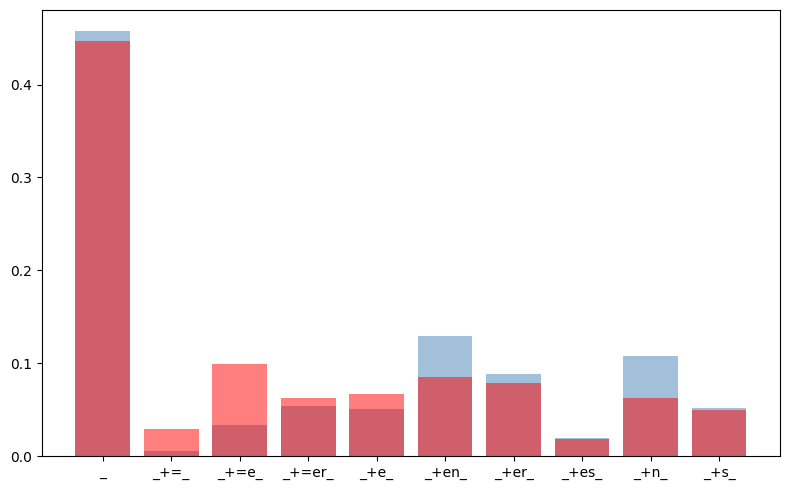

In [29]:
_, ax = plt.subplots(figsize=(8, 5))
ax.bar(linker_counts.values, linker_shares, color="steelblue", alpha=0.5)
ax.bar(linker_counts_300er.values, linker_shares_300er, color="red", alpha=0.5)
plt.tight_layout()
plt.show()

In [30]:
# p > 0.05 => the distributions are the same
mannwhitneyu(linker_shares, linker_shares_300er)

MannwhitneyuResult(statistic=np.float64(48.0), pvalue=np.float64(0.9096880762234906))

In [31]:
fcode_counts = np.unique_counts(gecodb_v07pl["freq_class_code"])
fcode_shares = fcode_counts.counts / fcode_counts.counts.sum()

fcode_counts_300er = np.unique_counts(gecodb_v07pl_300er["freq_class_code"])
fcode_shares_300er = fcode_counts_300er.counts / fcode_counts_300er.counts.sum()

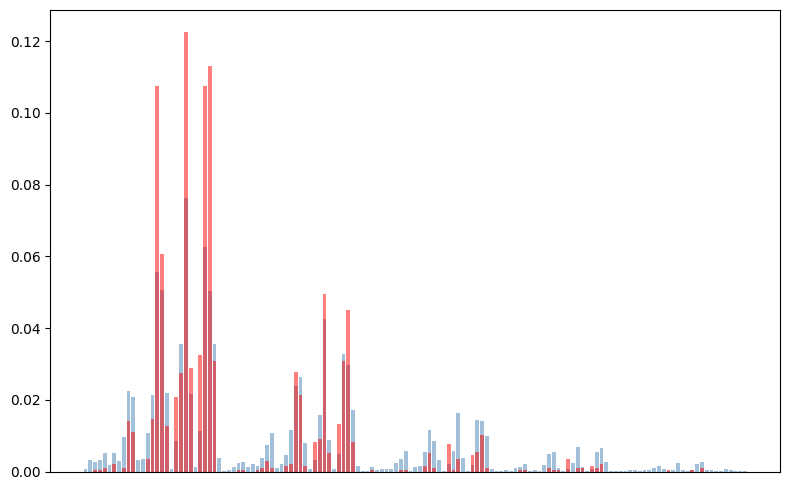

In [32]:
_, ax = plt.subplots(figsize=(8, 5))
ax.bar(fcode_counts.values, fcode_shares, color="steelblue", alpha=0.5)
ax.bar(fcode_counts_300er.values, fcode_shares_300er, color="red", alpha=0.5)
plt.xticks([])
plt.tight_layout()
plt.show()

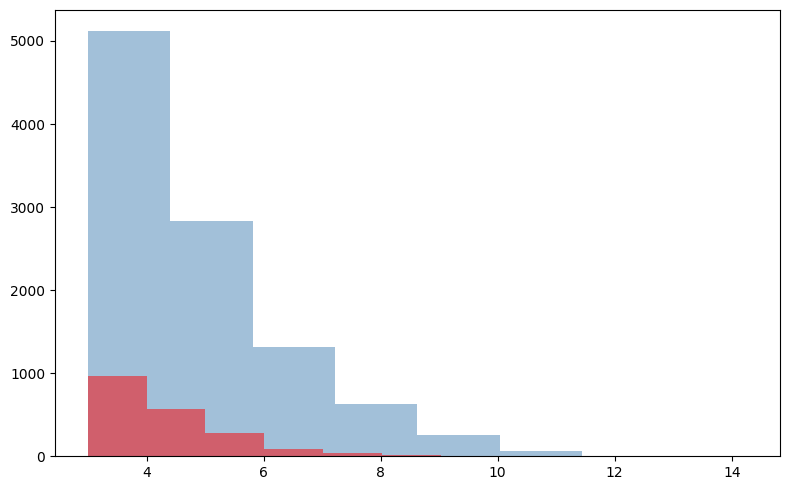

In [33]:
_, ax = plt.subplots(figsize=(8, 5))
ax.hist(np.log(gecodb_v07pl["comp_freq"]), bins=8, color="steelblue", alpha=0.5)
ax.hist(np.log(gecodb_v07pl_300er["comp_freq"]), bins=8, color="red", alpha=0.5)
plt.tight_layout()
plt.show()

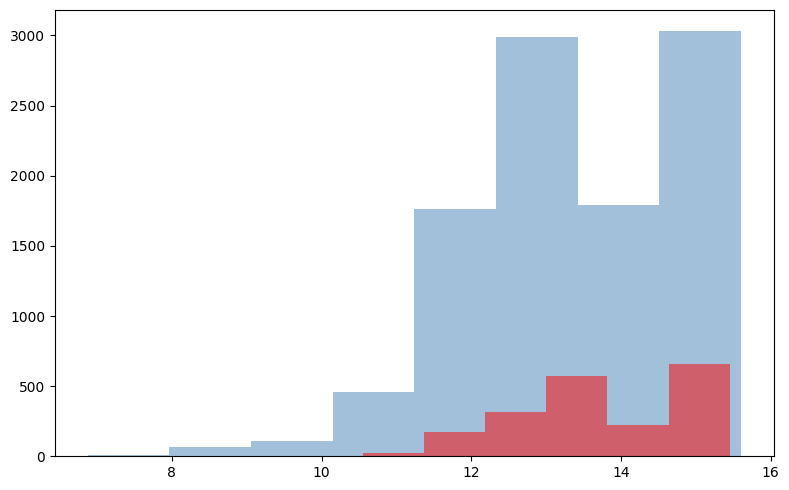

In [34]:
_, ax = plt.subplots(figsize=(8, 5))
ax.hist(np.log(gecodb_v07pl["n1_freq"]), bins=8, color="steelblue", alpha=0.5)
ax.hist(np.log(gecodb_v07pl_300er["n1_freq"]), bins=8, color="red", alpha=0.5)
plt.tight_layout()
plt.show()

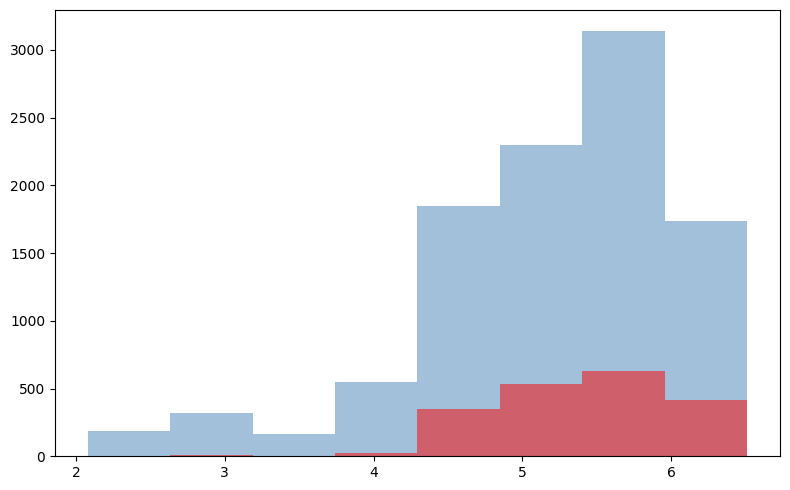

In [35]:
_, ax = plt.subplots(figsize=(8, 5))
ax.hist(np.log(gecodb_v07pl["n1_prod"]), bins=8, color="steelblue", alpha=0.5)
ax.hist(np.log(gecodb_v07pl_300er["n1_prod"]), bins=8, color="red", alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
gecodb_v07pl_300er.drop(columns=["freq_class_code", "freq_class_prob"], inplace=True)
gecodb_v07pl_300er.sort_values(by=["n1_freq", "linker"], ascending=False, inplace=True)
gecodb_v07pl_300er.to_csv(
    os.path.join(datadir, "gecodb_v07pl_300er_sample.tsv"),
    sep="\t",
    header=True,
    index=True
)